# Patient visits: pre vs post

**Exploration, not a pipeline step.** A patient's first visit (**pre**) and second visit (**post**), with a treatment in between. Part 1: the patients who can be compared, side by side. Part 2: one patient in detail.

**No statistical tests:** few patients and few visits. This is for looking only.

## Who can be compared, and what is assumed

**Only DBB (stroke), MAM (CBD) and JFR (PSP) can be compared:** they are the only patients with two visits. MFC, FCG, ISA and LSR were assessed once (no reassessment yet). If they come back, add their new sessions to `data/session_participant.csv` with `visit = 2` and they appear here.

**Assumptions, to be confirmed by Luana** (asked by email on 28/10/2026; written in `data/session_participant.csv`):
- **DBB pre** (29/06): the recordings at 10:44 and 10:47, no ID typed. Luana's time: 10:30.
- **MAM pre** (29/06): the recordings at 12:37, 12:40 and 12:51, no ID typed. Luana's time: 12:30.
- **MAM post** (11/08): the recording typed "MBM" at 17:09 is MAM. Luana's time: 16:00.
- **JFR pre** (10/07): the recordings from 15:24 to 15:34, no ID typed. **UNSURE:** Luana says 17:30, and nothing was recorded after 15:34 that day.
- **JFR post** (14/09): the recording typed "004" at 11:36 is JFR (same date and hour as Luana's reassessment).
- **Healthy reference:** the sessions without an ID, "anon" and the team tests (mostly June-July).

**Differences between the visits that do not come from the patient:**
- **Camera frame rate:** all 3 patients were filmed at about 17-19 frames per second pre and about 33 post. The jerk depends on it (section 2.5): **do not compare the jerk pre vs post.**
- **How the trials were ended:** almost all automatically before 02/09, all by the operator after (every session, patients included). DBB and MAM: both visits before 02/09 (same). JFR: pre automatic, post by the operator.
- **The healthy reference** was filmed at about 16-22 frames per second, with automatic trial ends.

Section 1.1 shows all this per recording, from the data.

Input: the cut movements of step 3 (`movement_cut.parquet`) and the trial tables of steps 1-3. Code: `measures.py` (in the repo folder).

In [1]:
%load_ext autoreload
%autoreload 2
import sys

sys.path.insert(0, "..")   # the code (measures.py, ...) is in the repo folder, one level up
import measures

## Settings
Change a value, then re-run from here. The two normalization switches can be used separately or together. `PATIENT` is only for Part 2.

In [2]:
PATIENT = "DBB"               # participant_id to look at
TASK_ID = 2                   # task to look at (1-8)
TIME_NORMALIZE = True         # True = every movement on the same time axis, 0-100 % of the movement
N_POINTS = 200                # points per movement when TIME_NORMALIZE is True
SIZE_NORMALIZE = False        # True = positions divided by the arm length (angles do not change)
ONLY_PASSING_TRIALS = True    # keep only trials with passes_checks
SKIP_FIRST_REPETITION = True  # leave out repetition 1 (practice trial)
SHOW_HEALTHY = True           # draw the healthy participants as a grey reference

In [3]:
# The settings collected for the functions.
settings = {"time_normalize": TIME_NORMALIZE, "n_points": N_POINTS, "size_normalize": SIZE_NORMALIZE,
            "only_passing_trials": ONLY_PASSING_TRIALS, "skip_first_repetition": SKIP_FIRST_REPETITION}

movement_cut, info = measures.load_data()
moments = measures.add_angles(movement_cut)               # the 2 angles at every moment
per_trial = measures.trial_measures(moments, info)        # one row per trial: coupling, angle ranges, jerk
selected = measures.select_trials(per_trial, settings)

three = measures.two_visit_trials(selected, info, TASK_ID)          # Part 1: the patients with 2 visits
patient = measures.patient_trials(selected, PATIENT, TASK_ID)       # Part 2: one patient
healthy = measures.healthy_trials(selected, TASK_ID, SHOW_HEALTHY)
drawn = selected[selected["trial_id"].isin(three["trial_id"]) | selected["trial_id"].isin(patient["trial_id"])
                 | selected["trial_id"].isin(healthy["trial_id"])]
curve_table = measures.curves(moments, drawn, measures.WRIST + measures.ANGLES, settings)
TASK_NAME = info.loc[info["task_id"] == TASK_ID, "task_name"].iloc[0]
print(f"Task {TASK_ID} ({TASK_NAME}): {len(three)} trials of {', '.join(sorted(three['person'].unique()))}; "
      f"healthy reference: {len(healthy)} trials from {healthy['person'].nunique()} persons")

Task 2 (Shoulder abduction with elbow extended): 141 trials of DBB, JFR, MAM; healthy reference: 31 trials from 3 persons


# Part 1: the 3 patients together

## 1.1 Their visits, from the data
One row per recording used here: which visit, when it was recorded, the ID typed during the recording (`(none)` = no ID typed), the number of trials (kept by step 3, all tasks), the camera frame rate, how many trials were ended by the operator, and the notes of `session_participant.csv` (the assignments made by hand, to be confirmed).

In [4]:
measures.visits_table(info)

,person,condition,visit_label,recorded,trials,frames_per_second,ended_by_operator_pct,typed_id,notes
0,DBB,Stroke,pre,29/06 10:47,289,17.0,10.0,(none),no ID typed; matched with Luana's date and hou...
1,DBB,Stroke,post,10/08 11:22,284,33.2,13.0,DBB,
2,JFR,PSP,pre,10/07 15:24,12,18.8,92.0,(none),UNSURE: no ID typed; Luana says 17:30 but noth...
3,JFR,PSP,pre,10/07 15:31,20,18.8,95.0,(none),UNSURE: no ID typed; Luana says 17:30 but noth...
4,JFR,PSP,pre,10/07 15:34,224,18.7,2.0,(none),UNSURE: no ID typed; Luana says 17:30 but noth...
5,JFR,PSP,post,14/09 11:36,265,32.8,100.0,004,"typed 004, corrected to JFR (same date and hou..."
6,MAM,CBD,pre,29/06 12:40,72,17.6,0.0,(none),no ID typed; matched with Luana's date and hou...
7,MAM,CBD,pre,29/06 12:51,192,17.3,1.0,(none),no ID typed; matched with Luana's date and hou...
8,MAM,CBD,post,11/08 17:09,270,33.2,3.0,MBM,"typed MBM, corrected to MAM (Luana says 16:00,..."


## 1.2 Movement over time, task `TASK_ID`
One row per patient, one panel per arm (`affected` / `less affected` once `affected_side` is filled in `participants.csv`, otherwise `left` / `right`). Every repetition as a thin line, the mean as a thick line, **pre in blue, post in orange**. Grey: healthy participants (median and 25-75 % band). Same y scale in every panel.

Choose what to draw in the next cell.

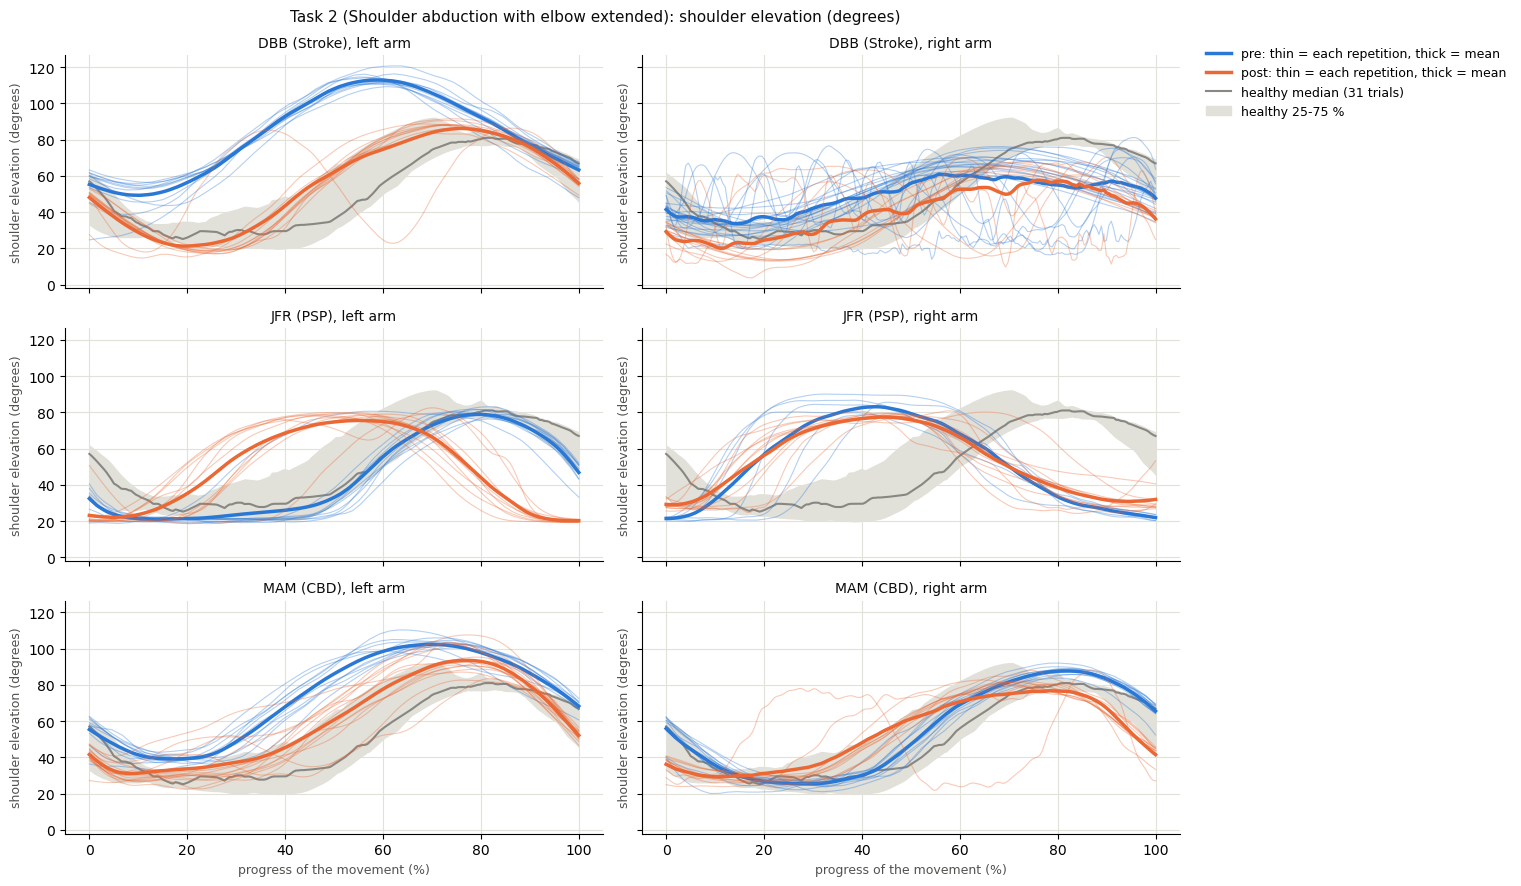

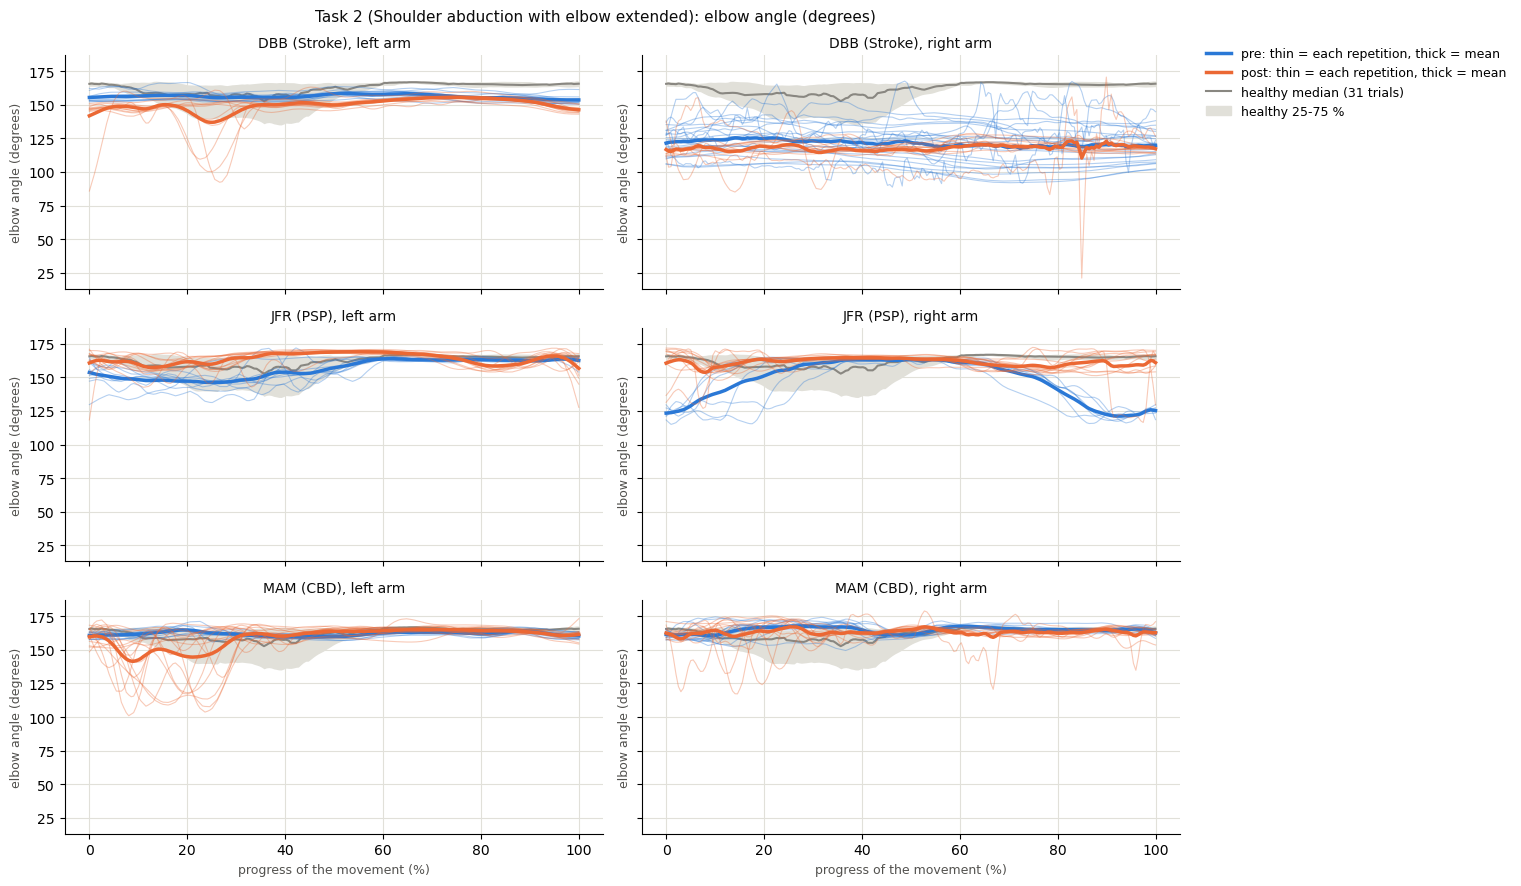

In [5]:
CURVES = ["shoulder_elevation_deg", "elbow_angle_deg"]   # any of: wrist_up, wrist_forward, wrist_out,
                                                         # shoulder_elevation_deg, elbow_angle_deg
for column in CURVES:
    measures.plot_curves_patients(curve_table, three, healthy["trial_id"], column, settings,
                                  f"Task {TASK_ID} ({TASK_NAME})")

## 1.3 Numbers per trial, task `TASK_ID`
One row per number, one column per patient. In each panel, for each arm: pre (blue), post (orange), then the healthy trials (grey). Each point = one trial, black line = median. Same y scale along a row.
- `movement_duration_s`: duration of the movement (cut in step 3).
- `shoulder_range_deg`: how much the arm goes up and down (largest − smallest shoulder elevation).
- `max_elbow_angle_deg`: how straight the arm gets (180 = straight).
- `coupling_r`: does the elbow open (+) or bend (−) while the arm goes up (section 2.4).
- `ldlj`: smoothness (closer to 0 = smoother). ⚠️ **Not comparable pre vs post here**: the camera rate changed between the visits (section 2.5).

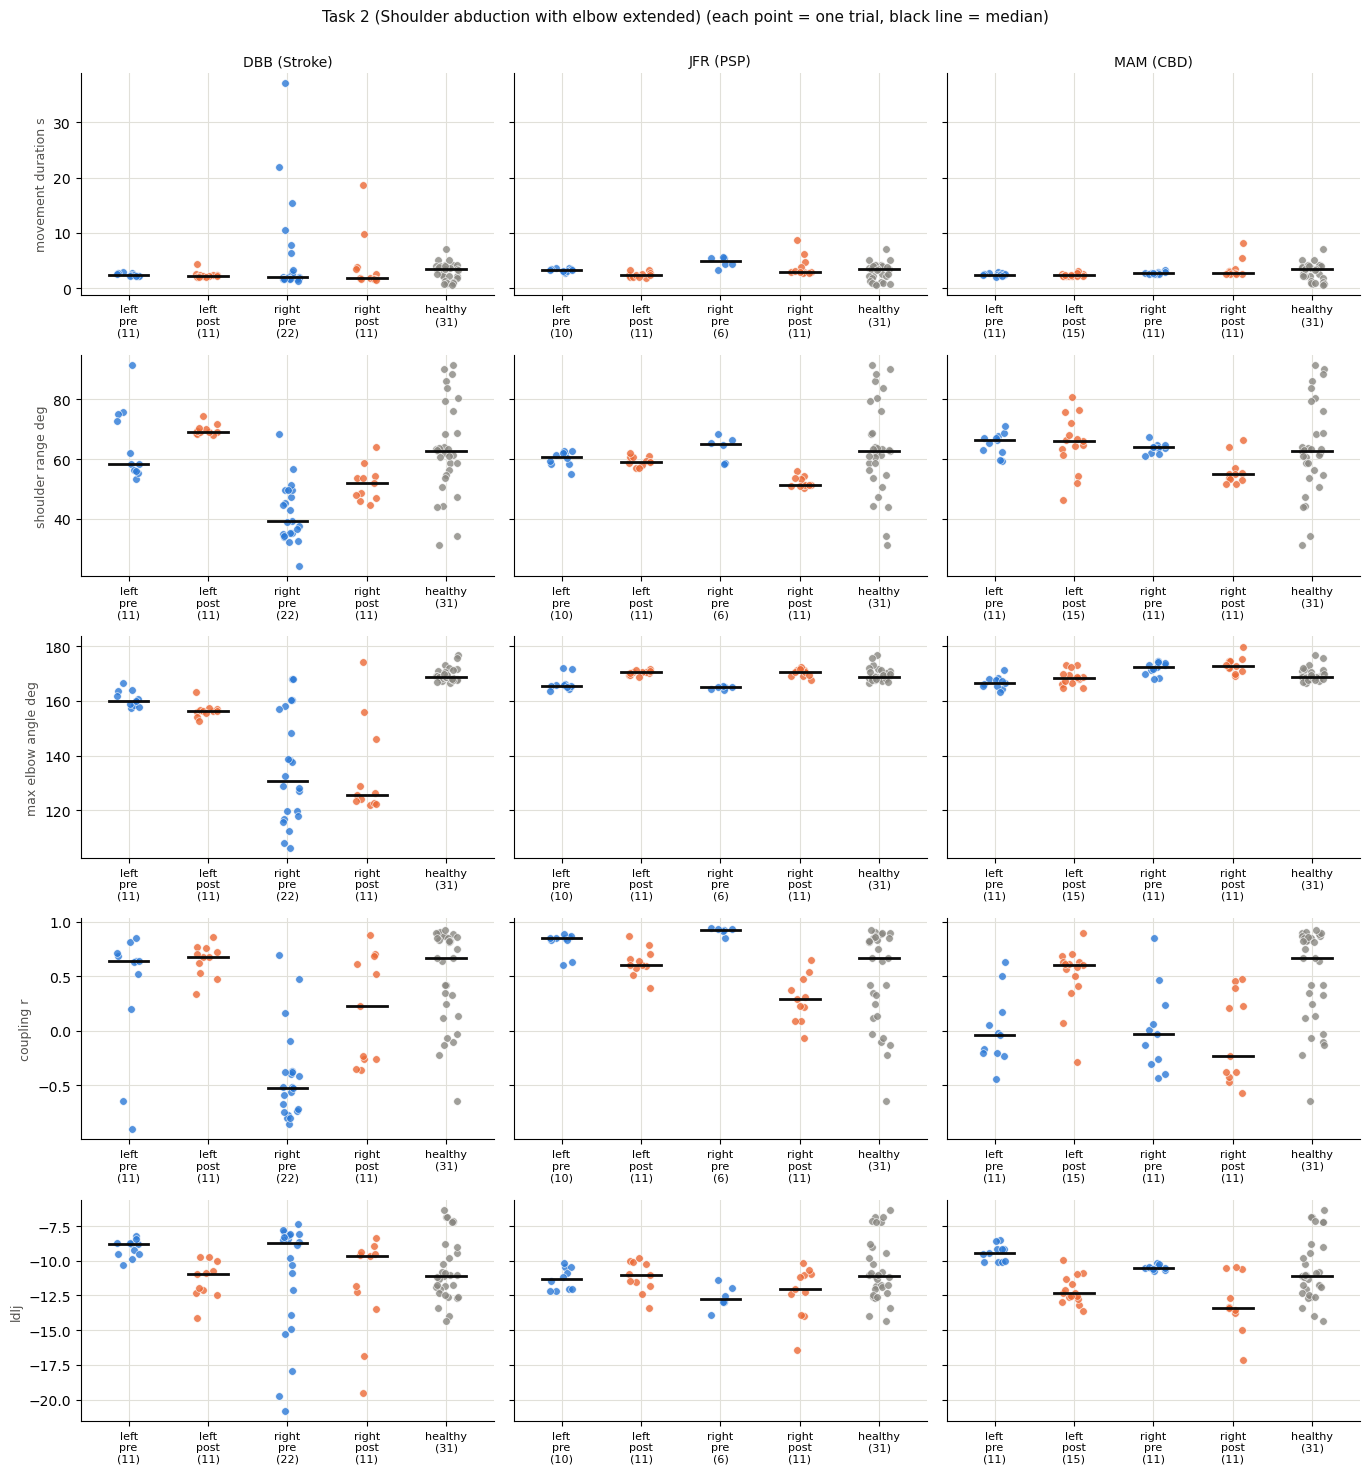

In [6]:
NUMBERS = ["movement_duration_s", "shoulder_range_deg", "max_elbow_angle_deg", "coupling_r", "ldlj"]

measures.plot_measures_patients(per_trial, three, healthy["trial_id"], NUMBERS, f"Task {TASK_ID} ({TASK_NAME})")

## 1.4 Summary, task `TASK_ID`
Per patient, visit and arm: number of trials and medians. The frame rate is shown because the jerk depends on it.

In [7]:
measures.summary_table(per_trial, three)

trials  movement_duration_s  \
person visit_label arm_label                                
DBB    pre         left           11                 2.30   
                   right          22                 2.04   
       post        left           11                 2.23   
                   right          11                 1.83   
JFR    pre         left           10                 3.26   
                   right           6                 4.93   
       post        left           11                 2.34   
                   right          11                 3.00   
MAM    pre         left           11                 2.45   
                   right          11                 2.67   
       post        left           15                 2.39   
                   right          11                 2.77   

                              max_elbow_angle_deg  shoulder_range_deg  \
person visit_label arm_label                                            
DBB    pre         left                    160.11               58.46   
                   right                   130.81               39.08   
       post        left                    156.39               69.18   
                   right                   125.60               52.04   
JFR    pre         left                    165.58               60.79   
                   right                   165.08               64.93   
       post        left                    170.50               59.16   
                   right                   170.59               51.31   
MAM    pre         left                    166.73               66.39   
                   right                   172.31               63.94   
       post        left                    168.58               66.06   
                   right                   172.86               54.84   

                              coupling_r   ldlj  frame_rate_hz  
person visit_label arm_label                                    
DBB    pre         left             0.64  -8.81          17.40  
                   right           -0.52  -8.75          16.76  
       post        left             0.68 -10.97          33.00  
                   right            0.23  -9.67          33.17  
JFR    pre         left             0.85 -11.28          18.49  
                   right            0.93 -12.74          19.03  
       post        left             0.60 -11.00          32.84  
                   right            0.29 -12.06          32.77  
MAM    pre         left            -0.04  -9.45          17.84  
                   right           -0.03 -10.52          17.35  
       post        left             0.61 -12.34          32.97  
                   right           -0.23 -13.37          33.30

# Part 2: one patient in detail (`PATIENT`)

## 2.0 What is available
For `PATIENT`: trials per visit and arm (rows) and task (columns), after the settings above, and the camera frame rate of each visit.

In [8]:
measures.visits_overview(selected, info, PATIENT)

Camera frame rate (median, frames per second): pre 17.0, post 33.2


task_id                 1   2   3   4   5   6   7   8
visit_label arm_label                                
pre         left       11  11  11  29  11  29  11  11
            right      11  22   7  40   9  29   9  11
post        left       11  11  11  29  11  36  14  10
            right      11  11  11  29  11  29   8  15

## 2.1 Movement curves
The wrist (from the shoulder, in the person's own directions: `up`, `forward`, `out`) over the movement: every repetition as a thin line, the mean as a thick line, **pre in blue, post in orange**, one panel per arm. Grey: healthy participants, same task (median line and 25-75 % band).

x axis: % of the movement (`TIME_NORMALIZE = True`) or seconds since the movement start (`False`: then the mean is drawn only where at least half of the trials are still going). Unit: metres, or arm lengths (`SIZE_NORMALIZE = True`).

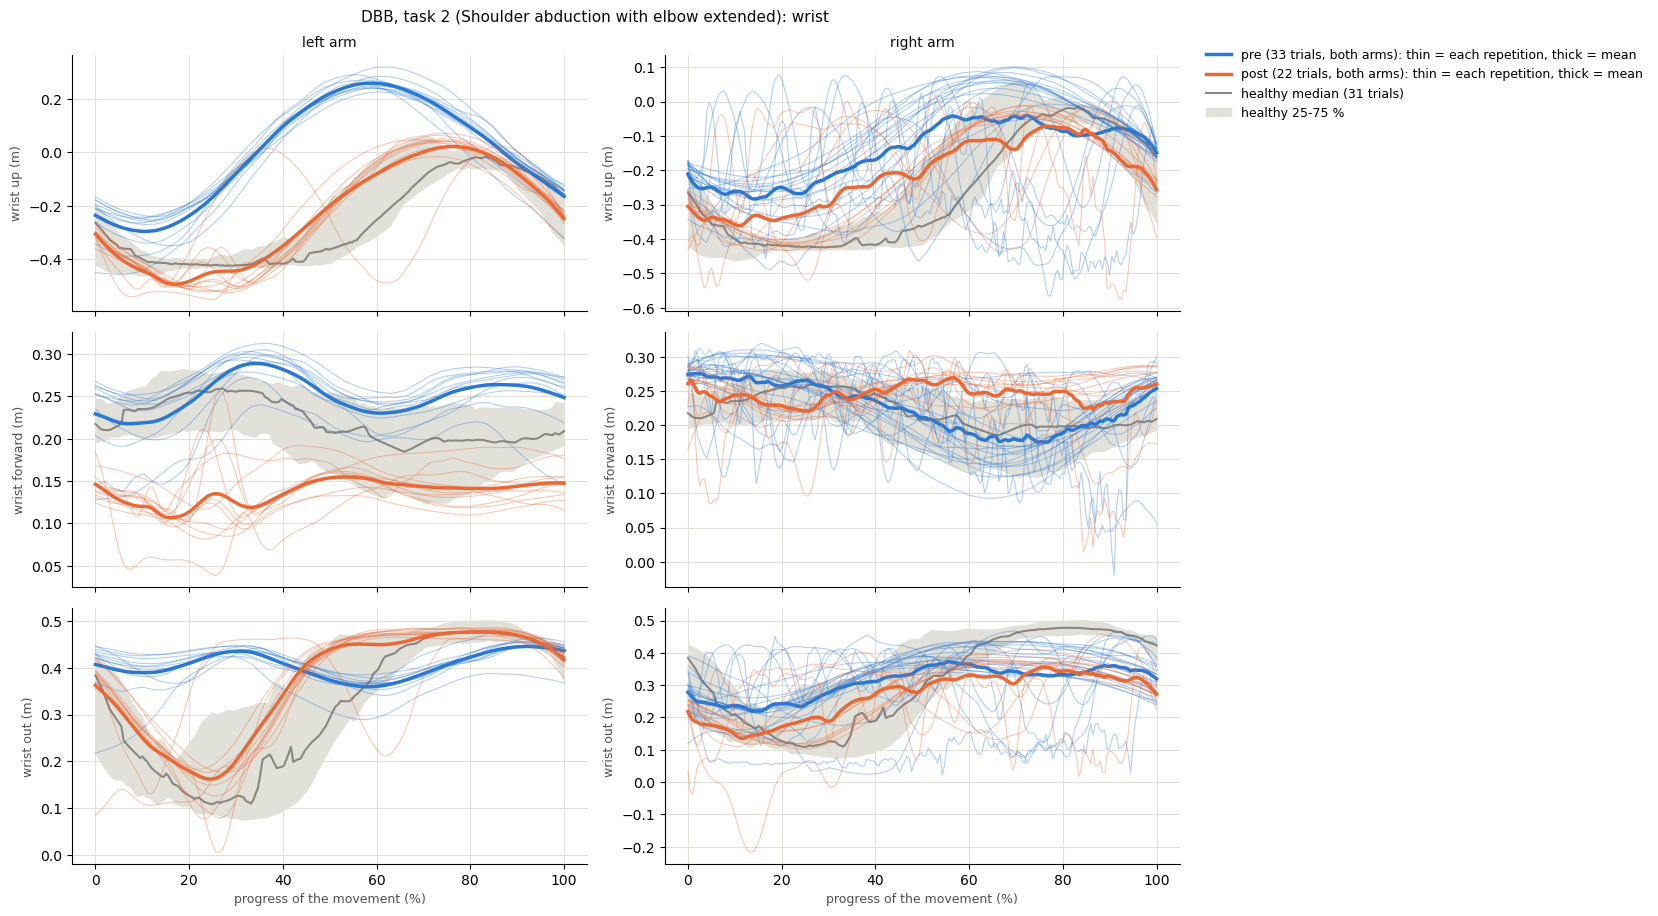

In [9]:
measures.plot_curves(curve_table, patient, healthy["trial_id"], ["wrist_up", "wrist_forward", "wrist_out"], settings,
                     f"{PATIENT}, task {TASK_ID} ({TASK_NAME}): wrist")

## 2.2 Angles over time
- `shoulder_elevation_deg`: angle between the upper arm and straight down (0 = arm hanging, 90 = horizontal, 180 = straight up).
- `elbow_angle_deg`: angle at the elbow between upper arm and forearm (180 = straight arm).

Same layout as 2.1. Angles do not change with `SIZE_NORMALIZE`.

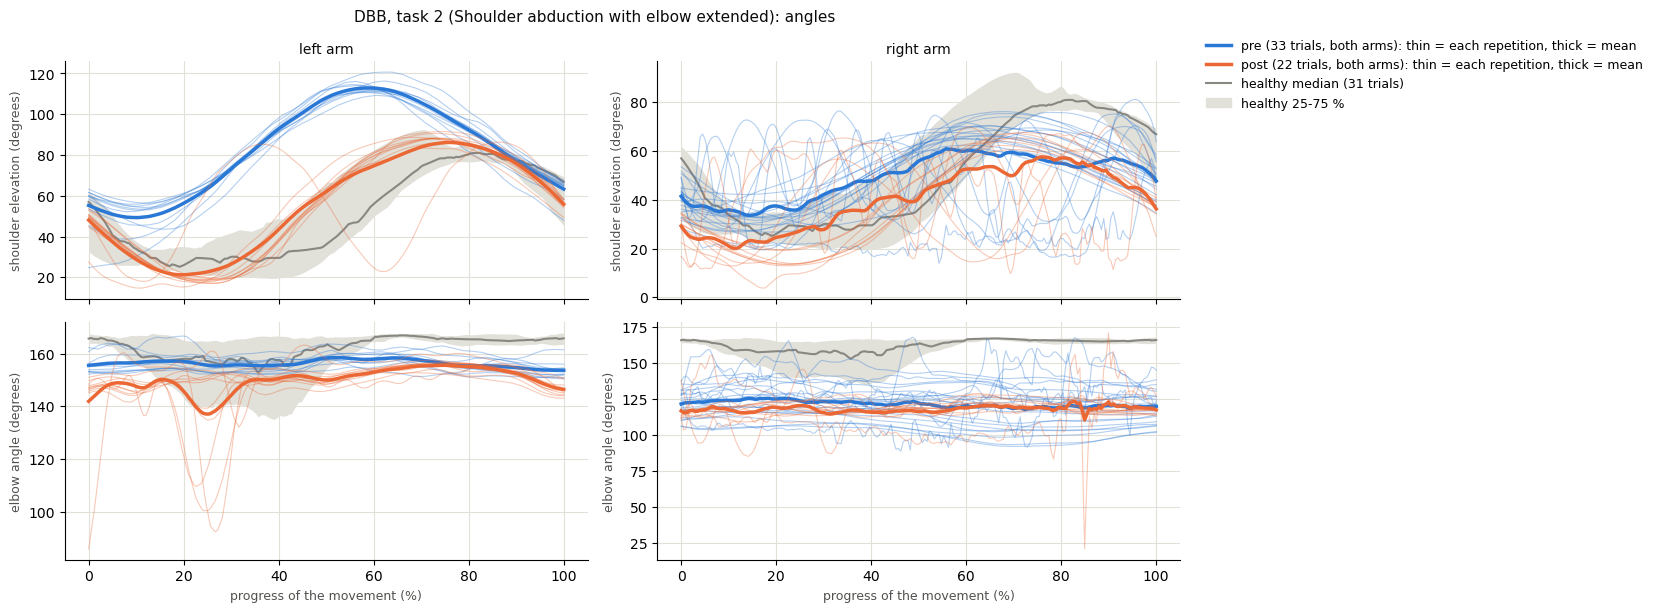

In [10]:
measures.plot_curves(curve_table, patient, healthy["trial_id"], ["shoulder_elevation_deg", "elbow_angle_deg"], settings,
                     f"{PATIENT}, task {TASK_ID} ({TASK_NAME}): angles")

## 2.3 Elbow angle
Top: how often each elbow angle occurs over all moments of the movement (each histogram scaled to an area of 1, so visits with more trials do not weigh more). Bottom: the largest elbow angle of each trial (how straight the arm gets).

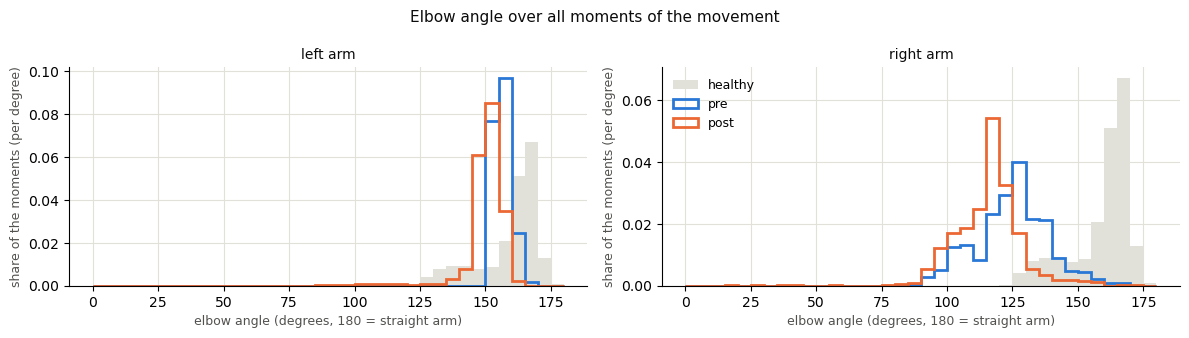

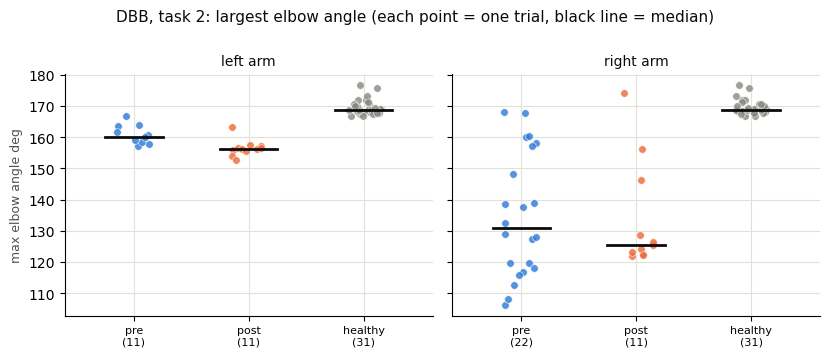

In [11]:
measures.plot_elbow_distribution(moments, patient, healthy["trial_id"])
measures.plot_trial_points(per_trial, patient, healthy["trial_id"], "max_elbow_angle_deg",
                           f"{PATIENT}, task {TASK_ID}: largest elbow angle")

## 2.4 Coupling between shoulder and elbow
Does the elbow open or bend while the arm goes up? Top: for each trial, shoulder elevation (x) against elbow angle (y), one line per trial. Bottom: per trial, the Pearson correlation between the 2 angles over the movement (+1 = the elbow opens as the arm goes up, −1 = it bends, 0 = no link).

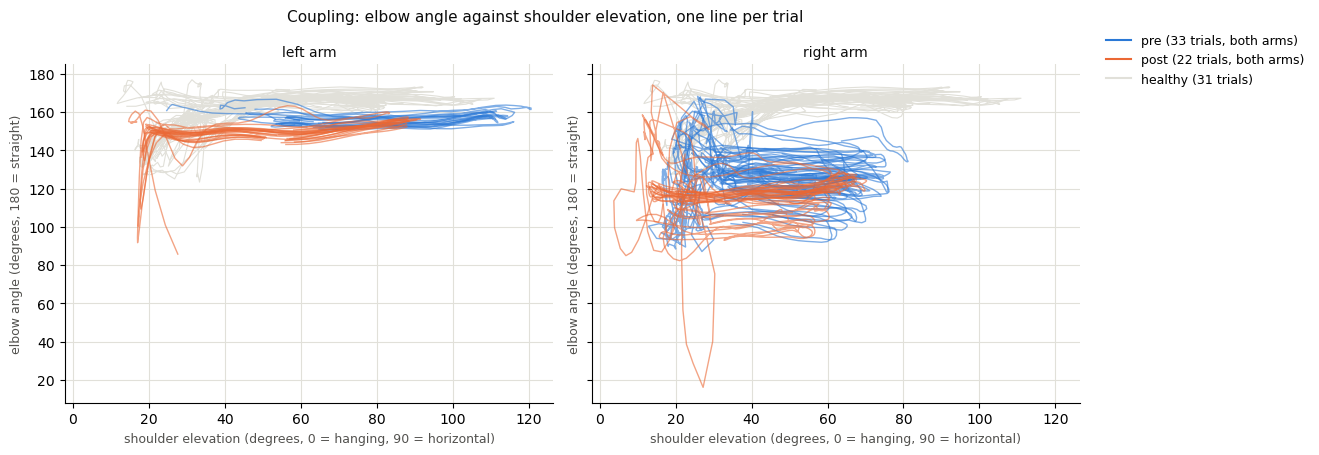

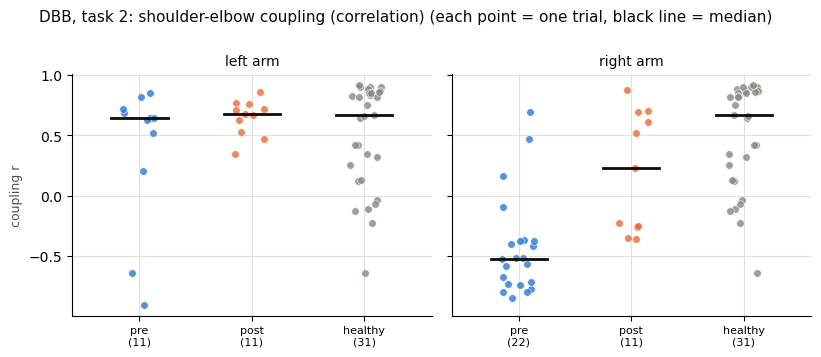

In [12]:
measures.plot_angle_paths(moments, patient, healthy["trial_id"])
measures.plot_trial_points(per_trial, patient, healthy["trial_id"], "coupling_r",
                           f"{PATIENT}, task {TASK_ID}: shoulder-elbow coupling (correlation)")

## 2.5 Jerk (smoothness of the wrist path)
- `mean_squared_jerk`: average of the squared jerk (third derivative of the position). Depends on the duration and size of the movement: log scale.
- `ldlj`: log dimensionless jerk (Balasubramanian et al. 2015). Does not depend on duration or size. Always negative, **closer to 0 = smoother**.

Both are computed on the real movement (seconds, metres), whatever the normalization settings.

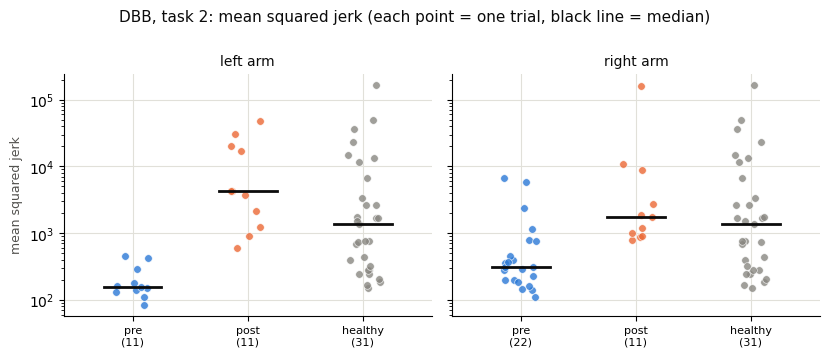

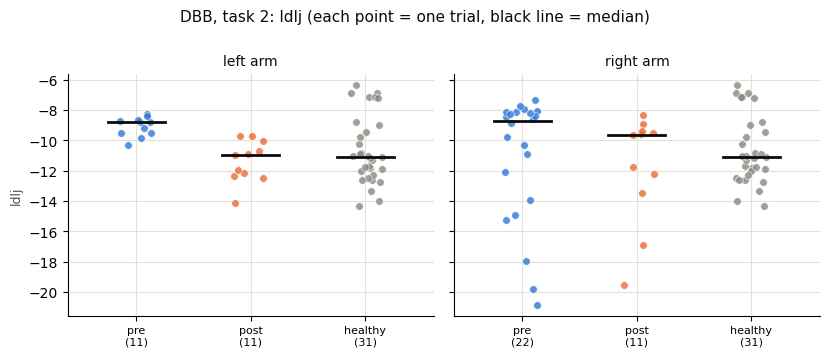

In [13]:
measures.plot_trial_points(per_trial, patient, healthy["trial_id"], "mean_squared_jerk",
                           f"{PATIENT}, task {TASK_ID}: mean squared jerk", log_scale=True)
measures.plot_trial_points(per_trial, patient, healthy["trial_id"], "ldlj", f"{PATIENT}, task {TASK_ID}: ldlj")

### Check: does the camera rate influence the jerk? (all trials)
The jerk is computed from the frames: with fewer frames per movement, the derivatives are less precise, which pulls `ldlj` towards 0. E.g. a perfectly smooth 0.8 s movement gives −5.32 (exact), −5.01 at 30 frames per second, −4.57 at 17. If `ldlj` and the frame rate are strongly related here, pre and post filmed at different rates cannot be compared on jerk.

⚠️ The rate is not a setting that changed once. June to mid-July (all healthy sessions and the first visits): about 16-22 frames per second. From 28/07 (the tracking setup changed, see `setup_version`): it varies from session to session (11 to 47) and even within a session (e.g. ISA 15-28). Patients: DBB, MAM, JFR 2nd visits, MFC, LSR about 33; FCG about 22; ISA about 17. The cause is not known yet (asked to Luana). The rate is also mixed with the people (healthy persons only at the low rates), so this correlation cannot separate the camera from the person. The perfectly smooth example above shows that the camera effect exists by itself.

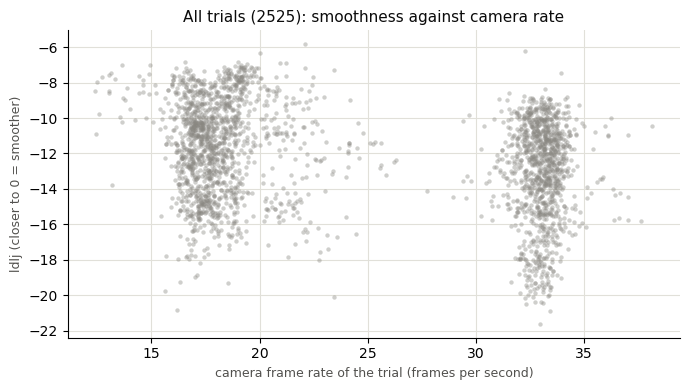

Strongly related (|r| >= 0.5) in 2 of 9 rows: the camera rate influences the jerk. Compare visits on jerk only if they were filmed at the same rate.


,,spearman_r
task_id,task_name,
1,Shoulder flexion with elbow extended,-0.29
2,Shoulder abduction with elbow extended,-0.18
3,Draw a 5 segment trajectory,-0.57
4,Reaching different targets,-0.36
5,Draw a circle,-0.55
6,Horizontal reaching,-0.24
7,Drinking test: reaching glass to mouth,-0.44
8,Index to nose,-0.39
all,all tasks,-0.22


In [14]:
measures.frame_rate_check(selected)

## 2.6 Summary for `PATIENT`
Per visit and arm: number of trials and medians.

In [15]:
measures.summary_table(per_trial, patient)

trials  movement_duration_s  \
person visit_label arm_label                                
DBB    pre         left           11                 2.30   
                   right          22                 2.04   
       post        left           11                 2.23   
                   right          11                 1.83   

                              max_elbow_angle_deg  shoulder_range_deg  \
person visit_label arm_label                                            
DBB    pre         left                    160.11               58.46   
                   right                   130.81               39.08   
       post        left                    156.39               69.18   
                   right                   125.60               52.04   

                              coupling_r   ldlj  frame_rate_hz  
person visit_label arm_label                                    
DBB    pre         left             0.64  -8.81          17.40  
                   right           -0.52  -8.75          16.76  
       post        left             0.68 -10.97          33.00  
                   right            0.23  -9.67          33.17